In [325]:
import numpy as np
import pandas as pd

np.random.seed(42) # for future 

"""Info about features and dataset

In [326]:
df=pd.read_csv("sgemm_product.csv")
print(f"Dataset shape:{df.shape}")
df.info()
print(df.describe())
print(df.head())

Dataset shape:(241600, 18)
<class 'pandas.DataFrame'>
RangeIndex: 241600 entries, 0 to 241599
Data columns (total 18 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   MWG        241600 non-null  int64  
 1   NWG        241600 non-null  int64  
 2   KWG        241600 non-null  int64  
 3   MDIMC      241600 non-null  int64  
 4   NDIMC      241600 non-null  int64  
 5   MDIMA      241600 non-null  int64  
 6   NDIMB      241600 non-null  int64  
 7   KWI        241600 non-null  int64  
 8   VWM        241600 non-null  int64  
 9   VWN        241600 non-null  int64  
 10  STRM       241600 non-null  int64  
 11  STRN       241600 non-null  int64  
 12  SA         241600 non-null  int64  
 13  SB         241600 non-null  int64  
 14  Run1 (ms)  241600 non-null  float64
 15  Run2 (ms)  241600 non-null  float64
 16  Run3 (ms)  241600 non-null  float64
 17  Run4 (ms)  241600 non-null  float64
dtypes: float64(4), int64(14)
memory usage: 33.2 MB
 

""" Separating features (first 14 columns) and target(last 4 columns)

In [327]:
X = df.iloc[:,:14].values
runs=df.iloc[:,14:18].values

""we can take every run column as target  but it is batter to take there avarage as target or log avarage (to make calculation simpler)

In [328]:
Y=np.log(np.mean(runs,axis=1))
print(Y)

[4.75677477 4.36570669 4.38906431 ... 3.55990907 3.34823603 2.88018112]


""" defining functions

In [329]:
# for MSE
def MSE(X,Y,W,bias):
    n=len(Y)
    XW=X.dot(W)
    y_pred=XW+bias
    y_diff=y_pred-Y
    return (1/(2*n))*(np.sum((y_diff)**2))

# partial derivative of Loss (MSE) w.r.t. W
def gradw(x,y,W,bias):
    n=len(y)
    y_pred=x.dot(W)+bias
    dlossdw=(1/n)*((x.T).dot(y_pred-y))
    return dlossdw

# partial derivative of Loss (MSE) w.r.t. Bias
def gradb(x,y,W,bias):
    n=len(y)
    y_pred=x.dot(W)+bias
    dlossdb=(1/n)*np.sum(y_pred-y)
    return dlossdb



Strategy 1: (Random with replacement)-for each epoch , run the update rules [deiling(N/batch size)] times . Each time, take number of data points (batch size) uniformly randomly and update the parameters.

In [330]:

def sgd_RWR(X,Y,alpha=0.01,epochs=100,batch_size=240, bias=0):

    m,n=X.shape #m row n col
    w=np.zeros(n)
    itt_per_epoch=int(np.ceil(m/batch_size))

    loss_plot=[]

    for i in range(epochs):
        for j in range(itt_per_epoch):

            indexes=np.random.choice(m,size=batch_size,replace=True)# permuted indexes

            X_batch=X[indexes]
            Y_batch=Y[indexes]

            dlossdw=gradw(X_batch,Y_batch,w,bias)
            w=w-(alpha*dlossdw)
            
            dlossdb=gradb(X_batch,Y_batch,w,bias)
            bias=bias-(alpha*dlossdb)

        loss=MSE(X,Y,w,bias)
        loss_plot.append(loss)
    return w,bias,loss_plot


Strategy 2:  (Random without replacement)- For each epoch, permute the data points randomly and create a list (say L). Divide this list into batches of the specified batch size and use each batch to update the model parameters. Here also, in each epoch, parameters will be updated [ceiling(N/batch size)] times.

In [331]:

def sgd_RWOR(X,Y,alpha=0.01,epochs=100,batch_size=240,bias=0):

    m,n=X.shape # m row n col
    w=np.zeros(n)

    loss_plot=[]

    for i in range(epochs):

        indexes=np.random.permutation(m) # permuted indexes
        L=X[indexes]
        X_permuted=L
        Y_permuted=Y[indexes]
        
        for j in range(0,m,batch_size):

            X_batch=X_permuted[j:j+batch_size]
            Y_batch=Y_permuted[j:j+batch_size]

            dlossdw=gradw(X_batch,Y_batch,w,bias)
            w=w-(alpha*dlossdw)

            dlossdb=gradb(X_batch,Y_batch,w,bias)
            bias=bias-(alpha*dlossdb)


        loss=MSE(X,Y,w,bias)
        loss_plot.append(loss)

    return w,bias,loss_plot

""" train test data split

In [332]:

from sklearn.model_selection import train_test_split

X_train,X_test,Y_train,Y_test =train_test_split(X,Y,test_size=0.2,random_state=42)

#Standardizing
mu,sigma=X_train.mean(axis=0),X_train.std(axis=0)
X_train=(X_train-mu)/sigma
X_test=(X_test-mu)/sigma


""" Training and Ploting
Fix at least 5 different batch sizes (say bs1, bs2, bs3, bs4, bs5), number epochs (say  100) and your data has N data points.

"" Strategy 1 :


Final Test MSE using Weight Vector from Strategy 1: 0.2790


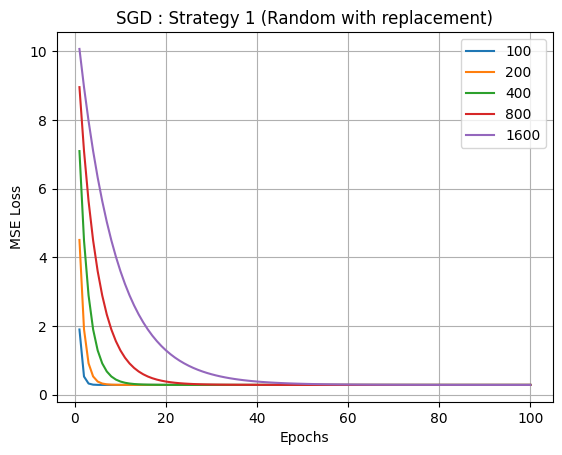

In [333]:
import matplotlib.pyplot as plt

Epochs=100
Alpha=0.00050 #learning rate
batch_sizes=[100,200,400,800,1600]

# Strategy 1
for i in range(len(batch_sizes)):

    w_1,bias1,yy1=sgd_RWR(X_train,Y_train,alpha=Alpha,epochs=Epochs,batch_size=batch_sizes[i])
    plt.plot(range(1,Epochs+1),yy1)

plt.title("SGD : Strategy 1 (Random with replacement)")
plt.grid()
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.legend(batch_sizes)

test_mse_1=MSE(X_test,Y_test,w_1,bias1)
print(f"\nFinal Test MSE using Weight Vector from Strategy 1: {test_mse_1:.4f}")

plt.show()

""Strategy 2:

Final Test MSE using Weight Vector from Strategy 2: 0.2790


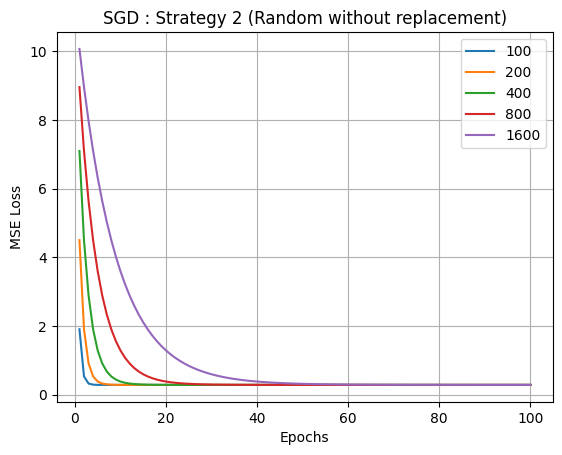

In [334]:

## Strategy 2
for i in range(len(batch_sizes)):

    w_2,bias2,yy2=sgd_RWOR(X_train,Y_train,alpha=Alpha,epochs=Epochs,batch_size=batch_sizes[i])
    plt.plot(range(1,Epochs+1),yy2)

plt.title("SGD : Strategy 2 (Random without replacement)")
plt.grid()
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.legend(batch_sizes)

test_mse_2=MSE(X_test,Y_test,w_2,bias2)
print(f"Final Test MSE using Weight Vector from Strategy 2: {test_mse_2:.4f}")

plt.show()


Both Strateges in same plot :

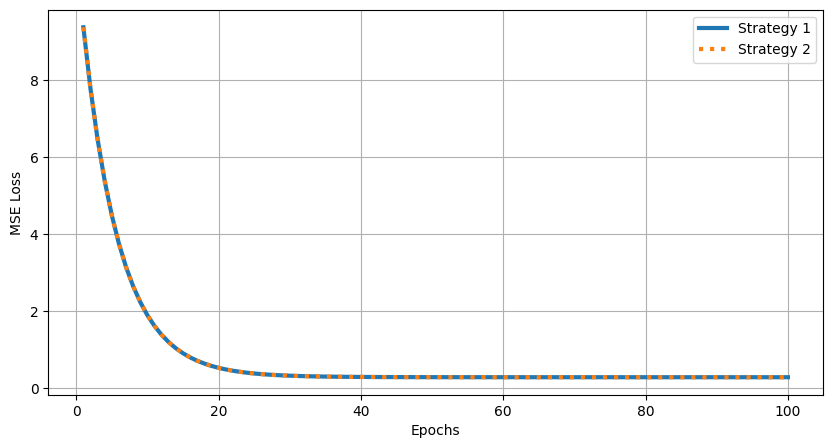

In [335]:
w_1,bias1,yy1=sgd_RWR(X_train,Y_train,alpha=Alpha,epochs=Epochs,batch_size=1000)
w_2,bias2,yy2=sgd_RWOR(X_train,Y_train,alpha=Alpha,epochs=Epochs,batch_size=1000)
plt.figure(figsize=(10, 5))
plt.plot(range(1,Epochs+1),yy1,linestyle="-",linewidth=3)
plt.plot(range(1,Epochs+1),yy2,linestyle=":",linewidth=3)
plt.legend(["Strategy 1","Strategy 2"])
plt.grid()
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")

plt.show()